# ĐỒ ÁN CUỐI KỲ: CSC17104 – LẬP TRÌNH CHO KHOA HỌC DỮ LIỆU
## PHẦN 2: PHÂN TÍCH CHUYÊN SÂU 5 CÂU HỎI NON-ML (Q1 - Q5) & TỔNG KẾT
---
Mỗi câu hỏi tuân thủ nghiêm ngặt 3 bước:
1. **Preprocessing:** Mô tả bằng Markdown, in và giải thích số dòng trước/sau.
2. **Analysis:** Giải thích phương pháp sử dụng và thực thi tính toán.
3. **Results:** Tối thiểu 2 biểu đồ chuẩn học thuật (đủ title, axes, units, legend, n), trả lời bằng số liệu cụ thể, thảo luận ý nghĩa thực tiễn, điểm bất ngờ và giới hạn.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append(os.path.abspath('..'))
from src.visualization import set_academic_style
from src.utils import check_row_count, calculate_aggregated_rate, calculate_asr, cluster_bootstrap_ci

set_academic_style()
print("Module và thiết lập trực quan hóa đã sẵn sàng!")

Module và thiết lập trực quan hóa đã sẵn sàng!


### Q1 (TV1): Xu hướng tỷ lệ tử vong toàn cầu: Mẫu cố định (Fixed Cohort) vs Mẫu đầy đủ (All Available)
- **Tiêu chí:** D2, D3, D6

### Q2 (TV1): Chênh lệch tỷ lệ tử vong Nam - Nữ theo độ tuổi và Khoảng tin cậy Bootstrap 95% CI
- **Tiêu chí:** D3, D4, D5

### Q3 · Biến động GDP/người và tỷ lệ tử vong trong cùng quốc gia

**3.3 · Đặc tả.** Khi GDP/người biến động, tỷ lệ ghi nhận thay đổi cùng hay ngược chiều? Quan hệ này khác nhau ra sao giữa ba nhóm GDP? Nhà phân tích chính sách an sinh có thể dùng kết quả để cân nhắc giá trị của GDP như một chỉ báo giám sát hằng năm.

**3.4 · Phương pháp.** Mỗi điểm là một cặp năm của cùng quốc gia. Tỷ lệ bằng 100.000 × tổng số ca / tổng dân số từ 5 tuổi. Sai phân loại thành phần cố định cộng tính của từng nước. Chia ba nhóm theo phân vị của GDP/người trung vị từng nước (USD hiện hành) trên các năm quan sát. Mỗi nước đóng góp một giá trị khi chia nhóm, mỗi cặp năm có trọng số bằng nhau khi ước lượng.

In [2]:
%matplotlib inline
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

root = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
sys.path.insert(0, str(root))
from src.economy_age import WHO, age_comparison, associations, changes, complete_years, country_years, period_cohort
from src.visualization import plot_age_shares, plot_crisis, plot_crude_asr, plot_gdp_changes, save_figure, set_academic_style

set_academic_style()
output = root / "data" / "processed"
full = complete_years(pd.read_csv(root / "data" / "raw" / "master.csv"))
panel = country_years(full)

[Nhãn hợp lệ, dân số dương và số ca không âm]


  • Số dòng trước : 27,820
  • Số dòng sau   : 27,820
  • Thay đổi      : +0 dòng (+0.00%)

[Đủ 6 nhóm tuổi × 2 giới tại mỗi quốc gia–năm]
  • Số dòng trước : 27,820
  • Số dòng sau   : 27,660
  • Thay đổi      : -160 dòng (-0.58%)

[Gộp thành quốc gia–năm, cộng số ca và dân số]
  • Số dòng trước : 27,660
  • Số dòng sau   : 2,305
  • Thay đổi      : -25,355 dòng (-91.67%)

[GDP bình quân dương để tính phần trăm]
  • Số dòng trước : 2,305
  • Số dòng sau   : 2,305
  • Thay đổi      : +0 dòng (+0.00%)



Ghép chính xác năm lịch để tính %ΔGDP và Δ tỷ lệ. Độ trễ hai năm đo thay đổi tích lũy từ t−2 đến t. Hai phép thử khác lần lượt loại các cặp có |%ΔGDP| > 20 và chỉ giữ các nước nhóm GDP cao. Hệ số dốc cho biết chênh lệch tỷ lệ ước tính ứng với 10 điểm phần trăm chênh lệch tăng trưởng GDP.

In [3]:
one_year = changes(panel, 1)
two_year = changes(panel, 2)
q3_stats = associations(one_year, two_year)
display(q3_stats.round(4))

[Có cùng nước ở đúng năm t−1]
  • Số dòng trước : 2,305
  • Số dòng sau   : 2,148
  • Thay đổi      : -157 dòng (-6.81%)

[Có cùng nước ở đúng năm t−2]
  • Số dòng trước : 2,305
  • Số dòng sau   : 2,028
  • Thay đổi      : -277 dòng (-12.02%)



,Số cặp,Số nước,Pearson r,Spearman ρ,Δ tỷ lệ / +10% GDP
Mẫu,,,,,
1 năm,2148,96,-0.0289,-0.0544,-0.0449
2 năm,2028,94,-0.0737,-0.0982,-0.0771
"1 năm, |ΔGDP| ≤ 20%",1828,96,-0.0129,-0.0156,-0.0292
"1 năm, GDP thấp",655,32,-0.0140,-0.0747,-0.0236
"1 năm, GDP trung bình",735,32,-0.0639,-0.0665,-0.1007
"1 năm, GDP cao",758,32,-0.0043,-0.0198,-0.0056


-> Đã lưu biểu đồ: C:\Users\Hai Dang\Desktop\lab_KHDL\HCMUS_HKD_TV2\data\processed\tv2_q3_gdp.png


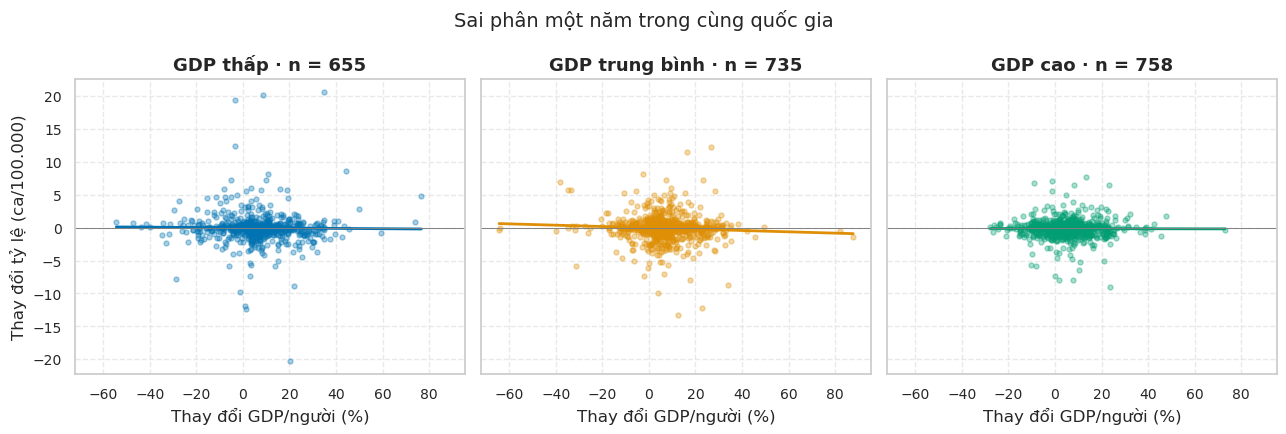

In [4]:
fig = plot_gdp_changes(one_year)
save_figure(fig, output / "tv2_q3_gdp.png")
plt.show()

-> Đã lưu biểu đồ: C:\Users\Hai Dang\Desktop\lab_KHDL\HCMUS_HKD_TV2\data\processed\tv2_q3_crisis.png


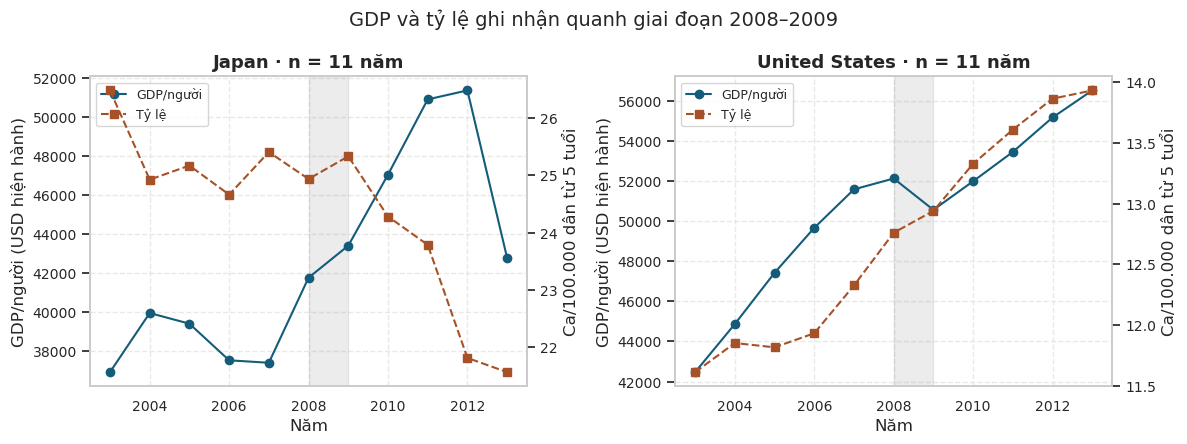

In [5]:
fig = plot_crisis(panel)
save_figure(fig, output / "tv2_q3_crisis.png")
plt.show()

### Q4 · Cơ cấu tuổi và thay đổi tỷ lệ giữa hai giai đoạn

**3.3 · Đặc tả.** Trong các nước có dữ liệu đủ, bao nhiêu phần biến động tỷ lệ thô đi cùng dịch chuyển cơ cấu tuổi? Người phụ trách giám sát dịch tễ có thể đối chiếu tỷ lệ thô với tỷ lệ chuẩn hóa trước khi đánh giá biến động sức khỏe dân số.

**3.4 · Phương pháp.** Hai cửa sổ 1995–2000 và 2010–2015 đều gồm sáu năm, tính cả hai đầu. Giữ cùng các nước đủ 12 tổ hợp tuổi–giới ở cả 12 năm. Cộng số ca và dân số qua từng giai đoạn rồi tính tỷ lệ cho từng nhóm tuổi. ASR = tổng của tỷ lệ theo tuổi nhân trọng số cố định. Bộ trọng số thứ hai lấy từ tổng dân số theo tuổi của toàn bộ quốc gia–năm đủ nhóm. Cả hai chuẩn đều quy về dân số từ 5 tuổi. Hai giới được gộp trong từng nhóm tuổi.

Nguồn trọng số WHO 2000–2025, cột WHO World Standard (%). [Bảng quy đổi của NCI/SEER](https://seer.cancer.gov/stdpopulations/world.who.html)

In [6]:
cohort = period_cohort(full)
empirical = full.groupby("age").population.sum()
weights = pd.DataFrame({"WHO": WHO / WHO.sum(), "Mẫu": empirical / empirical.sum()}).loc[WHO.index]
display(weights.round(4))
q4_rates, q4_delta, q4_shares = age_comparison(cohort, empirical)
pooled_rates, pooled_delta, pooled_shares = age_comparison(cohort, empirical, by_country=False)
display(pooled_rates.round(3), pooled_delta.round(3))
display(q4_delta.nlargest(15, "Δ dân số 55+ (điểm %)").round(3))

[Hai cửa sổ, mỗi cửa sổ 6 năm lịch]
  • Số dòng trước : 27,660
  • Số dòng sau   : 11,460
  • Thay đổi      : -16,200 dòng (-58.57%)

[Cùng quốc gia đủ cả 12 năm]
  • Số dòng trước : 11,460
  • Số dòng sau   : 7,056
  • Thay đổi      : -4,404 dòng (-38.43%)



,WHO,Mẫu
5-14 years,0.1896,0.1641
15-24 years,0.1831,0.1684
25-34 years,0.1704,0.1644
35-54 years,0.2758,0.2799
55-74 years,0.1474,0.1713
75+ years,0.0336,0.0518


[Cộng số ca và dân số theo giai đoạn và nhóm tuổi]
  • Số dòng trước : 7,056
  • Số dòng sau   : 588
  • Thay đổi      : -6,468 dòng (-91.67%)

[Cộng số ca và dân số theo giai đoạn và nhóm tuổi]
  • Số dòng trước : 7,056
  • Số dòng sau   : 12
  • Thay đổi      : -7,044 dòng (-99.83%)



,WHO,Mẫu,Thô
period,,,
1995–2000,13.858,14.654,14.515
2010–2015,11.252,11.843,12.428


,Δ WHO,Δ Mẫu,Δ Thô,Cơ cấu tuổi,Tỷ lệ theo tuổi,Cơ cấu / Δ thô (%),Δ dân số 55+ (điểm %)
country,,,,,,,
Tất cả nước trong mẫu,-2.607,-2.81,-2.087,0.809,-2.896,-38.751,4.61


,Δ WHO,Δ Mẫu,Δ Thô,Cơ cấu tuổi,Tỷ lệ theo tuổi,Cơ cấu / Δ thô (%),Δ dân số 55+ (điểm %)
country,,,,,,,
Malta,1.554,1.563,1.887,0.203,1.684,10.754,10.279
Japan,-0.073,-0.623,-0.433,1.855,-2.288,-428.518,10.264
Singapore,-2.434,-2.985,-1.118,1.372,-2.489,-122.717,9.154
Republic of Korea,10.434,11.754,15.277,3.732,11.545,24.430,9.028
Finland,-8.687,-8.929,-9.319,0.105,-9.423,-1.122,8.353
Czech Republic,-2.099,-2.415,-1.325,1.373,-2.698,-103.646,7.620
Slovenia,-10.940,-11.322,-9.647,2.698,-12.345,-27.966,7.345
Mauritius,-5.079,-5.169,-5.160,0.086,-5.247,-1.675,7.134
Croatia,-5.922,-6.411,-4.726,2.517,-7.243,-53.249,6.922


**Phân rã thay đổi tỷ lệ thô.** Với từng nhóm tuổi, nhân thay đổi tỷ trọng dân số với trung bình hai tỷ lệ riêng rồi cộng để được thành phần cơ cấu tuổi. Thành phần còn lại bằng thay đổi tỷ lệ riêng nhân tỷ trọng trung bình. Hai thành phần cộng đúng bằng Δ thô. Tỷ phần cơ cấu = 100 × thành phần cơ cấu / Δ thô. Giá trị âm nghĩa là cơ cấu tuổi và thay đổi ròng đi ngược chiều. Tỷ phần có thể vượt 100% khi hai thành phần bù trừ và không xác định khi thay đổi ròng bằng 0. Đây là phép phân rã mô tả.

-> Đã lưu biểu đồ: C:\Users\Hai Dang\Desktop\lab_KHDL\HCMUS_HKD_TV2\data\processed\tv2_q4_asr.png


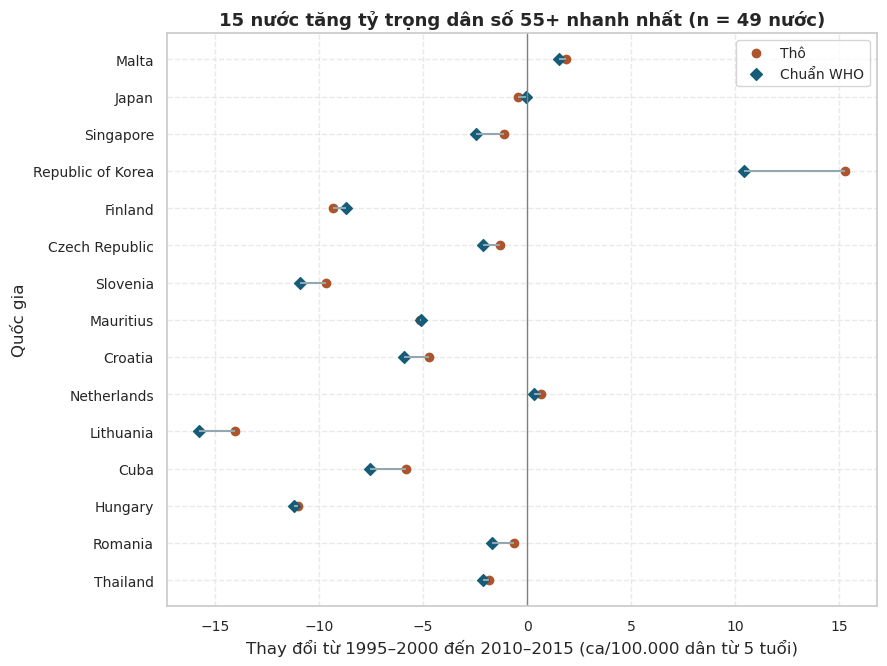

In [7]:
fig = plot_crude_asr(q4_delta)
save_figure(fig, output / "tv2_q4_asr.png")
plt.show()

-> Đã lưu biểu đồ: C:\Users\Hai Dang\Desktop\lab_KHDL\HCMUS_HKD_TV2\data\processed\tv2_q4_age.png


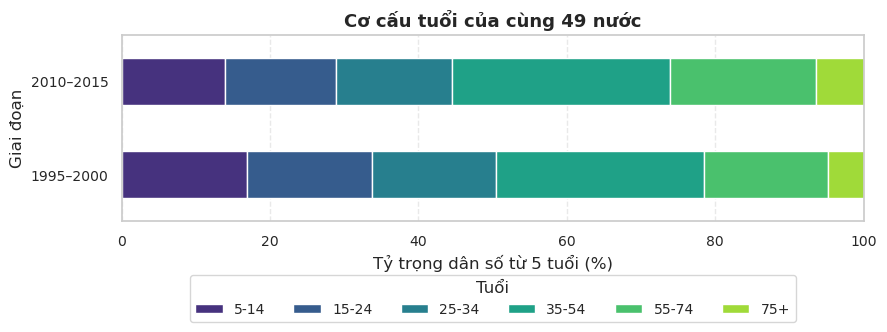

In [8]:
fig = plot_age_shares(pooled_shares, len(q4_delta))
save_figure(fig, output / "tv2_q4_age.png")
plt.show()

### Q5 (TV3): Khảo sát dữ liệu thiếu của HDI và sai lệch ước lượng theo độ tuổi & vùng địa lý
- **Tiêu chí:** D1, D2, D3, D4, D5, D6

#### 3.3. Đặc tả câu hỏi Q5

**Câu hỏi:** Chỉ số phát triển con người (`HDI for year`) bị thiếu như thế nào theo quốc gia, khu vực và thời gian? Nếu chỉ giữ các dòng có HDI (*complete-case analysis*) thì ước lượng tỷ lệ tự tử theo nhóm tuổi và khu vực bị lệch bao nhiêu?

- **Người dùng mục tiêu:** người phân tích dữ liệu y tế công cộng muốn đưa HDI vào mô hình (hồi quy, dự báo) trên bộ dữ liệu này.
- **Động cơ:** cột HDI thiếu 69.94% (mục 3.2.4). Nhiều phân tích mặc định bỏ các dòng thiếu. Nếu dữ liệu không thiếu hoàn toàn ngẫu nhiên (MCAR) thì cách đó làm sai lệch kết luận.
- **Quyết định được hỗ trợ:** có nên dùng HDI làm biến giải thích hay không; nếu dùng thì có được bỏ các dòng thiếu không, hay phải phân tích riêng hoặc tìm nguồn HDI khác.

**Tiêu chí chiều sâu:**

| Tiêu chí | Cách làm trong Q5 |
|---|---|
| D1 – Ghép dữ liệu | Ghép bảng vùng và nhóm thu nhập của World Bank theo tên nước, báo cáo các khóa không khớp |
| D2 – Thời gian | Ma trận thiếu HDI theo quốc gia × năm; tách "thiếu theo năm" và "thiếu theo nước" |
| D3 – Biến phái sinh | Cờ `is_missing_hdi`, loại thiếu `missing_type`, độ lệch tương đối Bias% |
| D4 – Phân tầng | Bias% theo 6 nhóm tuổi, giới tính, giai đoạn và khu vực |
| D5 – Bất định | Kiểm định Mann-Whitney U và Kolmogorov-Smirnov; khoảng tin cậy 95% bằng cluster bootstrap theo quốc gia |
| D6 – Độ vững | Bỏ nước có ảnh hưởng lớn, chỉ giữ nước có độ phủ HDI cao, đổi tỷ lệ gộp sang trung vị |

#### 3.4. Q5 – Tiền xử lý

1. Đọc `master.csv`, đổi tên cột cho gọn, **loại năm 2016** (chỉ 16 nước và thiếu nhóm 5-14, xem mục 3.2.4).
2. **(D1)** Ghép `data/raw/country_region.csv` để có khu vực và nhóm thu nhập của từng nước.
3. **(D3)** Tạo cờ thiếu HDI và phân loại nguồn thiếu.

Tỷ lệ luôn tính theo công thức gộp $100{,}000 \times \sum \text{ca} / \sum \text{dân số}$, không lấy trung bình cột `suicides/100k pop`.

In [2]:
%matplotlib inline
from IPython.display import display
from scipy import stats
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from src.visualization import save_figure

# Bước 1: đọc dữ liệu, đổi tên cột, loại năm 2016
q5_raw = pd.read_csv(os.path.join('..', 'data', 'raw', 'master.csv'))
q5 = q5_raw.rename(columns={
    'suicides/100k pop': 'rate',
    'HDI for year': 'hdi',
    ' gdp_for_year ($) ': 'gdp_for_year',
    'gdp_per_capita ($)': 'gdp_per_capita',
})
q5_before = q5
q5 = q5[q5['year'] != 2016].copy()
check_row_count(q5_before, q5, "Q5 - Loại năm 2016")
print("Nước chỉ có số liệu năm 2016 (bị loại theo):",
      sorted(set(q5_before['country']) - set(q5['country'])))

[Q5 - Loại năm 2016]
  • Số dòng trước : 27,820
  • Số dòng sau   : 27,660
  • Thay đổi      : -160 dòng (-0.58%)

Nước chỉ có số liệu năm 2016 (bị loại theo): ['Mongolia']


**Bước 2 (D1): ghép khu vực và nhóm thu nhập.**

- **Nguồn:** World Bank, *Country and Lending Groups*, lấy qua API `https://api.worldbank.org/v2/country?format=json&per_page=400` ngày 23/11/2026, giấy phép CC BY 4.0. File `data/raw/country_region.csv` giữ 217 nền kinh tế (đã bỏ các dòng tổng hợp như "World", "High income") với 4 cột: `iso3`, `country_wb`, `region`, `income_group`.
- **Khóa ghép:** tên nước. Hai nguồn đặt tên khác nhau, nên em ghép thử bằng tên gốc để liệt kê các tên không khớp, chuẩn hóa bằng một bảng ánh xạ tường minh, rồi mới ghép thật với `validate='many_to_one'` (mỗi nước chỉ có một dòng trong bảng vùng).
- **Lưu ý:** `income_group` là phân loại **hiện tại** của World Bank, không phải phân loại theo từng năm 1985–2015.

In [3]:
q5_regions = pd.read_csv(os.path.join('..', 'data', 'raw', 'country_region.csv'))
assert q5_regions['country_wb'].is_unique
print(f"country_region.csv: {len(q5_regions)} nền kinh tế")

# Ghép thử bằng tên gốc để tìm khóa không khớp
q5_names = pd.Series(sorted(q5['country'].unique()))
q5_unmatched = q5_names[~q5_names.isin(q5_regions['country_wb'])]
print(f"Số nước trong dữ liệu: {len(q5_names)}, "
      f"không khớp tên: {len(q5_unmatched)}")

# Bảng ánh xạ tên của dữ liệu gốc -> tên của World Bank
Q5_NAME_MAP = {
    'Bahamas': 'Bahamas, The',
    'Czech Republic': 'Czechia',
    'Kyrgyzstan': 'Kyrgyz Republic',
    'Macau': 'Macao SAR, China',
    'Puerto Rico': 'Puerto Rico (US)',
    'Republic of Korea': 'Korea, Rep.',
    'Saint Kitts and Nevis': 'St. Kitts and Nevis',
    'Saint Lucia': 'St. Lucia',
    'Saint Vincent and Grenadines': 'St. Vincent and the Grenadines',
    'Slovakia': 'Slovak Republic',
    'Turkey': 'Turkiye',
}
assert set(Q5_NAME_MAP) == set(q5_unmatched)
assert set(Q5_NAME_MAP.values()) <= set(q5_regions['country_wb'])
display(pd.DataFrame({'Tên trong master.csv': list(Q5_NAME_MAP),
                      'Tên World Bank': list(Q5_NAME_MAP.values())}))

q5['country_wb'] = q5['country'].replace(Q5_NAME_MAP)
q5_before = q5
q5 = q5.merge(q5_regions, on='country_wb', how='left',
              validate='many_to_one')
check_row_count(q5_before, q5, "Q5 - Ghép khu vực World Bank (D1)")
print("Số dòng chưa có khu vực sau khi chuẩn hóa tên:",
      q5['region'].isna().sum())

# Tên khu vực tiếng Việt cho biểu đồ
Q5_REGION_VI = {
    'Europe & Central Asia': 'Châu Âu & Trung Á',
    'Latin America & Caribbean': 'Mỹ Latinh & Caribe',
    'East Asia & Pacific': 'Đông Á & Thái Bình Dương',
    'Middle East, North Africa, Afghanistan & Pakistan':
        'Trung Đông & Bắc Phi (gồm AF, PK)',
    'Sub-Saharan Africa': 'Châu Phi hạ Sahara',
    'North America': 'Bắc Mỹ',
    'South Asia': 'Nam Á',
}
q5['region_vi'] = q5['region'].map(Q5_REGION_VI)
q5_countries = q5.drop_duplicates('country')
display(q5_countries.groupby('region_vi').size()
        .sort_values(ascending=False).rename('Số quốc gia').to_frame())

country_region.csv: 217 nền kinh tế
Số nước trong dữ liệu: 100, không khớp tên: 11


,Tên trong master.csv,Tên World Bank
0,Bahamas,"Bahamas, The"
1,Czech Republic,Czechia
2,Kyrgyzstan,Kyrgyz Republic
3,Macau,"Macao SAR, China"
4,Puerto Rico,Puerto Rico (US)
5,Republic of Korea,"Korea, Rep."
6,Saint Kitts and Nevis,St. Kitts and Nevis
7,Saint Lucia,St. Lucia
8,Saint Vincent and Grenadines,St. Vincent and the Grenadines
9,Slovakia,Slovak Republic


[Q5 - Ghép khu vực World Bank (D1)]
  • Số dòng trước : 27,660
  • Số dòng sau   : 27,660
  • Thay đổi      : +0 dòng (+0.00%)

Số dòng chưa có khu vực sau khi chuẩn hóa tên: 0


,Số quốc gia
region_vi,
Châu Âu & Trung Á,46
Mỹ Latinh & Caribe,29
Đông Á & Thái Bình Dương,10
"Trung Đông & Bắc Phi (gồm AF, PK)",7
Châu Phi hạ Sahara,4
Bắc Mỹ,2
Nam Á,2


In [4]:
# Bước 3 (D3): cờ thiếu HDI và phân loại nguồn thiếu
q5_hdi_years = sorted(q5.loc[q5['hdi'].notna(), 'year'].unique())
q5['is_missing_hdi'] = q5['hdi'].isna()
q5['in_hdi_year'] = q5['year'].isin(q5_hdi_years)
q5['missing_type'] = np.select(
    [~q5['is_missing_hdi'], ~q5['in_hdi_year']],
    ['Có HDI', 'Thiếu theo năm'],
    default='Thiếu theo nước',
)
print("Các năm có HDI:", q5_hdi_years)

q5_cy = q5.drop_duplicates(['country', 'year'])
q5_type_table = pd.DataFrame({
    'Số dòng': q5['missing_type'].value_counts(),
    'Số cặp country-year': q5_cy['missing_type'].value_counts(),
})
q5_type_table['% số dòng'] = (100 * q5_type_table['Số dòng']
                              / len(q5)).round(2)
display(q5_type_table)

Các năm có HDI: [1985, 1990, 1995, 2000, 2005, 2010, 2011, 2012, 2013, 2014]


,Số dòng,Số cặp country-year,% số dòng
missing_type,,,
Thiếu theo năm,18384,1532,66.46
Có HDI,8364,697,30.24
Thiếu theo nước,912,76,3.30


#### 3.4. Q5 – Phân tích

**a) Thiếu theo thời gian và theo quốc gia (D2).** Ma trận dưới đây có mỗi hàng là một quốc gia (xếp theo khu vực) và mỗi cột là một năm. Ô xám là năm nước đó không có trong dữ liệu, ô cam là có số liệu tự tử nhưng thiếu HDI, ô xanh là có HDI.

-> Đã lưu biểu đồ: ../data/processed/tv3_q5_fig1_hdi_matrix.png


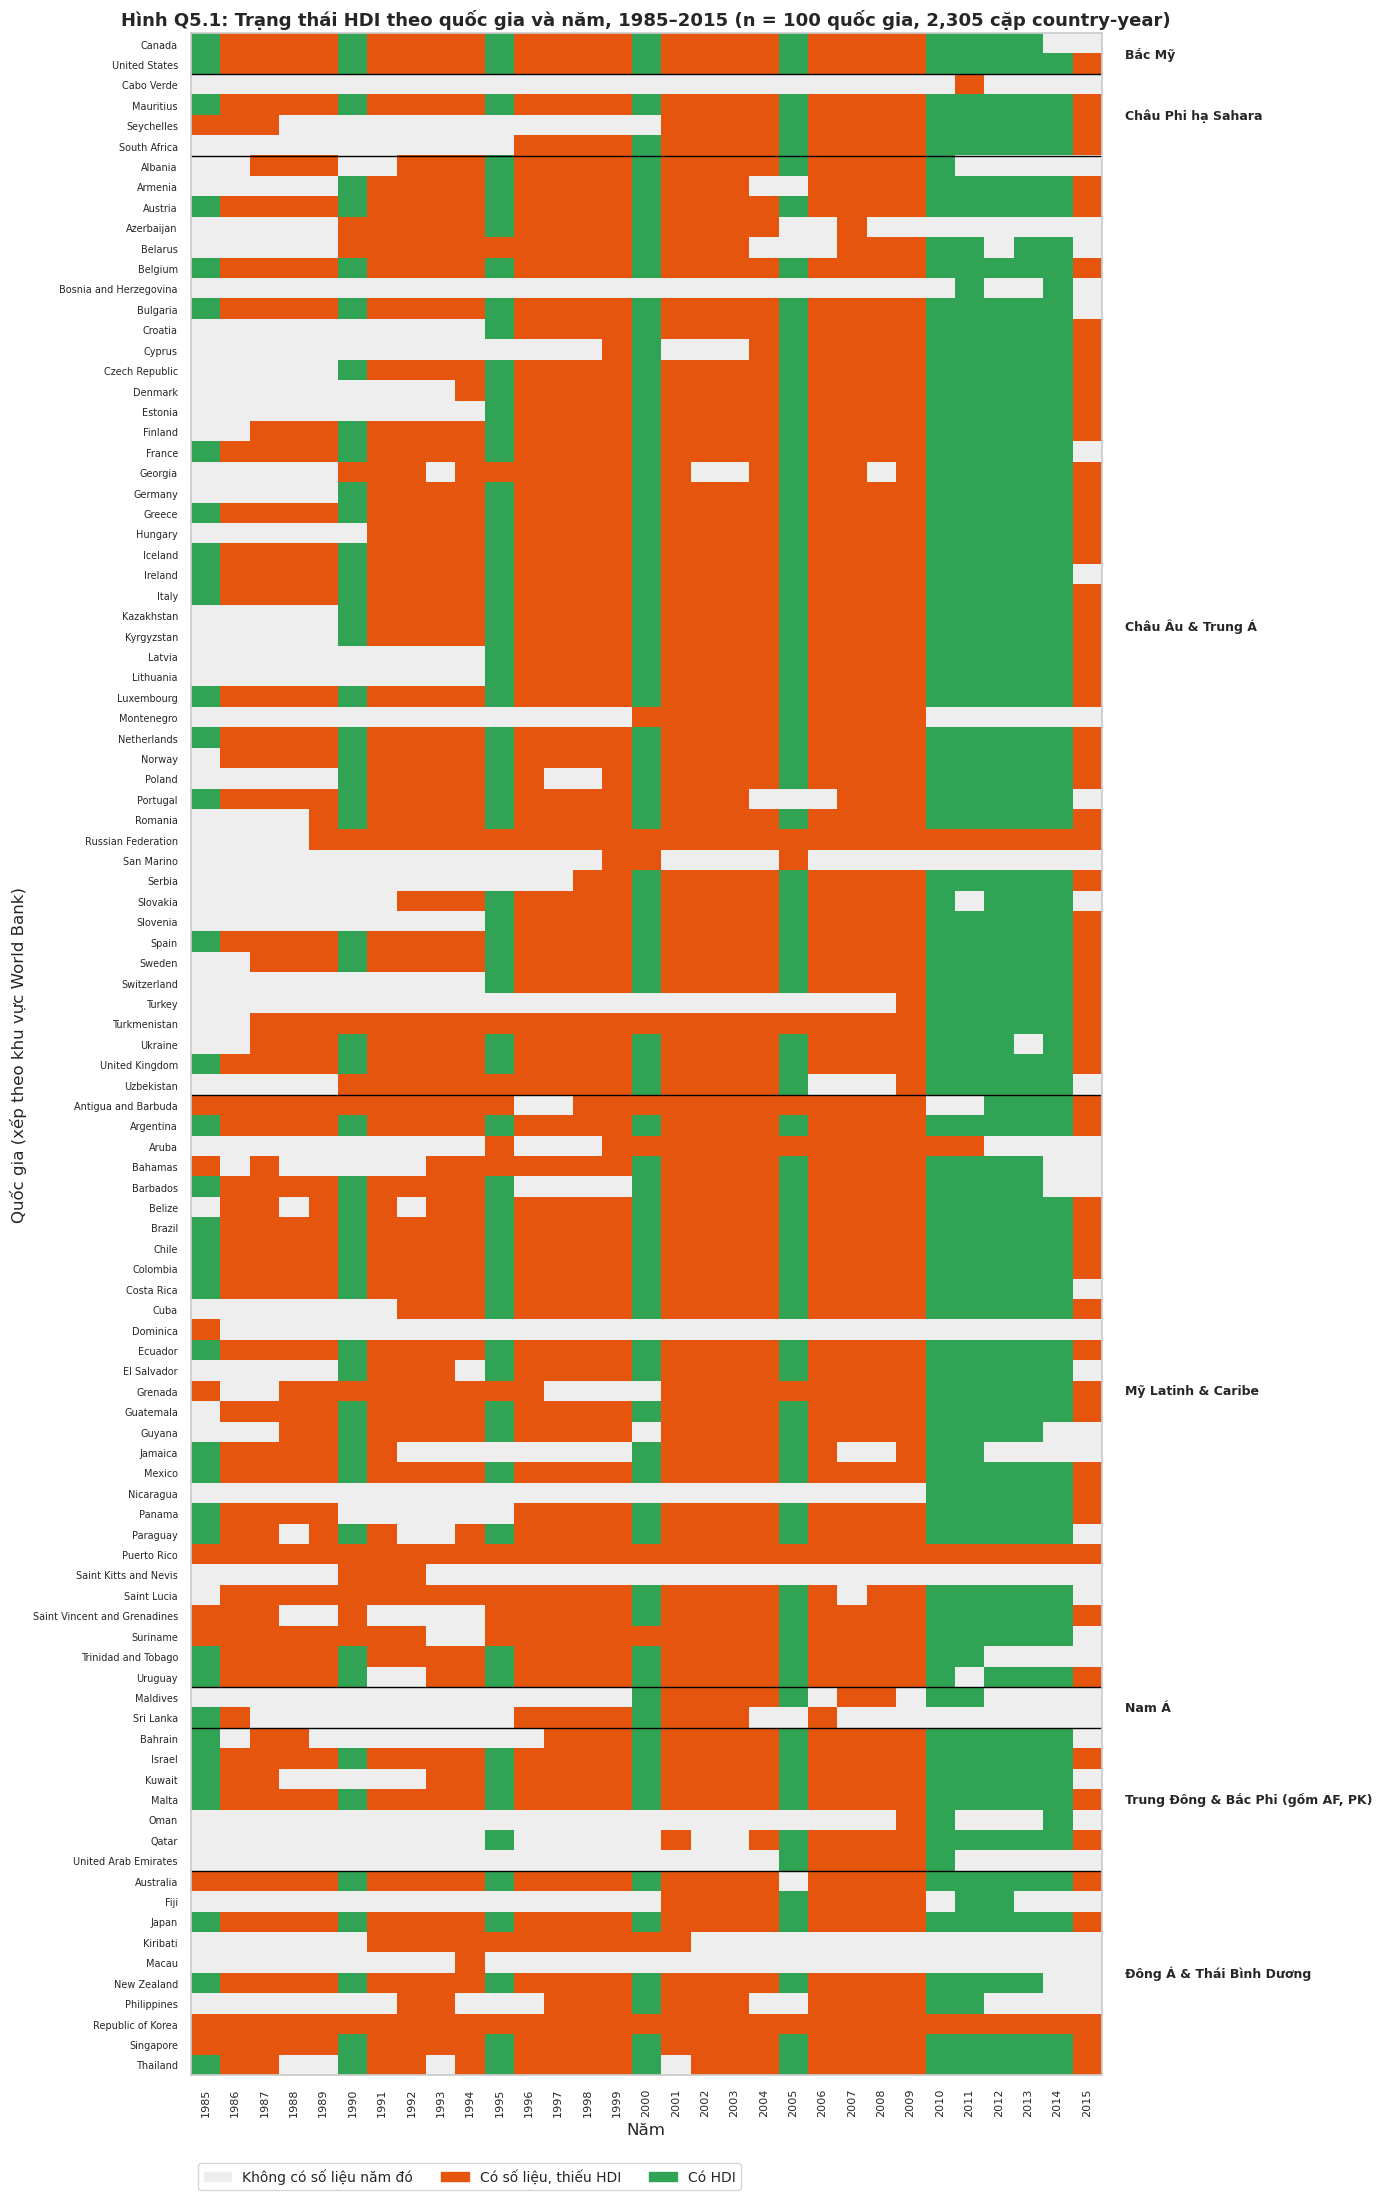

Tỷ lệ country-year có HDI trong 10 năm có HDI (21 năm còn lại đều 0%):


year,1985,1990,1995,2000,2005,2010,2011,2012,2013,2014
Số country-year,48.0,64.0,78.0,86.0,84.0,88.0,86.0,81.0,80.0,78.0
% có HDI,77.1,78.1,80.8,88.4,90.5,95.5,94.2,96.3,96.2,96.2


In [5]:
q5_status = (q5_cy.assign(code=np.where(q5_cy['is_missing_hdi'], 1, 2))
             .pivot(index='country', columns='year', values='code')
             .reindex(columns=range(1985, 2016))
             .fillna(0))
q5_order = q5_countries.sort_values(['region_vi', 'country'])
q5_status = q5_status.loc[q5_order['country']]

fig, ax = plt.subplots(figsize=(14, 22))
cmap = ListedColormap(['#eeeeee', '#e6550d', '#31a354'])
ax.imshow(q5_status.to_numpy(), aspect='auto', cmap=cmap,
          vmin=0, vmax=2, interpolation='none')
ax.set_xticks(range(q5_status.shape[1]))
ax.set_xticklabels(q5_status.columns, rotation=90, fontsize=8)
ax.set_yticks(range(q5_status.shape[0]))
ax.set_yticklabels(q5_status.index, fontsize=7)
ax.grid(False)

# Đường phân cách và nhãn khu vực
q5_bounds = q5_order['region_vi'].to_numpy()
for i in range(1, len(q5_bounds)):
    if q5_bounds[i] != q5_bounds[i - 1]:
        ax.axhline(i - 0.5, color='black', linewidth=1)
for reg_name, pos in (q5_order.reset_index(drop=True)
                      .groupby('region_vi').groups.items()):
    ax.text(q5_status.shape[1] + 0.3, np.mean(pos), reg_name,
            va='center', fontsize=9, fontweight='bold')

ax.legend(handles=[Patch(color='#eeeeee', label='Không có số liệu năm đó'),
                   Patch(color='#e6550d', label='Có số liệu, thiếu HDI'),
                   Patch(color='#31a354', label='Có HDI')],
          loc='upper left', bbox_to_anchor=(0, -0.04), ncol=3)
ax.set_xlabel('Năm')
ax.set_ylabel('Quốc gia (xếp theo khu vực World Bank)')
ax.set_title('Hình Q5.1: Trạng thái HDI theo quốc gia và năm, 1985–2015 '
             f'(n = {q5_status.shape[0]} quốc gia, '
             f'{len(q5_cy):,} cặp country-year)')
fig.tight_layout()
save_figure(fig, '../data/processed/tv3_q5_fig1_hdi_matrix.png')
plt.show()

# Tỷ lệ country-year có HDI theo năm: các năm ngoài 10 năm có HDI đều là 0%
q5_by_year = q5_cy.groupby('year')['is_missing_hdi'].agg(['size', 'mean'])
q5_by_year['% có HDI'] = (100 * (1 - q5_by_year['mean'])).round(1)
assert (q5_by_year.drop(index=q5_hdi_years)['% có HDI'] == 0).all()
print("Tỷ lệ country-year có HDI trong 10 năm có HDI "
      "(21 năm còn lại đều 0%):")
display(q5_by_year.loc[q5_hdi_years]
        .rename(columns={'size': 'Số country-year'})
        [['Số country-year', '% có HDI']].T)

**b) Thiếu theo khu vực và nhóm thu nhập (D1, D4).** Để tách khỏi "thiếu theo năm" (năm đó cả thế giới không có HDI), phần này chỉ xét **10 năm có HDI**. Đơn vị đếm là cặp country-year.

,so_quoc_gia,so_country_year,pct_thieu
region_vi,,,
Đông Á & Thái Bình Dương,9,66,21.2
Mỹ Latinh & Caribe,29,237,15.6
Châu Phi hạ Sahara,4,25,8.0
Châu Âu & Trung Á,46,372,6.2
Bắc Mỹ,2,19,0.0
Nam Á,2,6,0.0
"Trung Đông & Bắc Phi (gồm AF, PK)",7,48,0.0


,so_quoc_gia,so_country_year,pct_thieu
income_group,,,
Lower middle income,4,25,16.0
Upper middle income,36,253,9.9
High income,59,495,9.5


Nước có mặt trong 10 năm có HDI nhưng không bao giờ có HDI: 9


,region_vi,income_group
country,,
Aruba,Mỹ Latinh & Caribe,High income
Cabo Verde,Châu Phi hạ Sahara,Upper middle income
Dominica,Mỹ Latinh & Caribe,Upper middle income
Kiribati,Đông Á & Thái Bình Dương,Lower middle income
Puerto Rico,Mỹ Latinh & Caribe,High income
Republic of Korea,Đông Á & Thái Bình Dương,High income
Russian Federation,Châu Âu & Trung Á,High income
Saint Kitts and Nevis,Mỹ Latinh & Caribe,High income
San Marino,Châu Âu & Trung Á,High income


Nước không có dòng nào trong 10 năm có HDI: ['Macau']


-> Đã lưu biểu đồ: ../data/processed/tv3_q5_fig2_missing_by_region.png


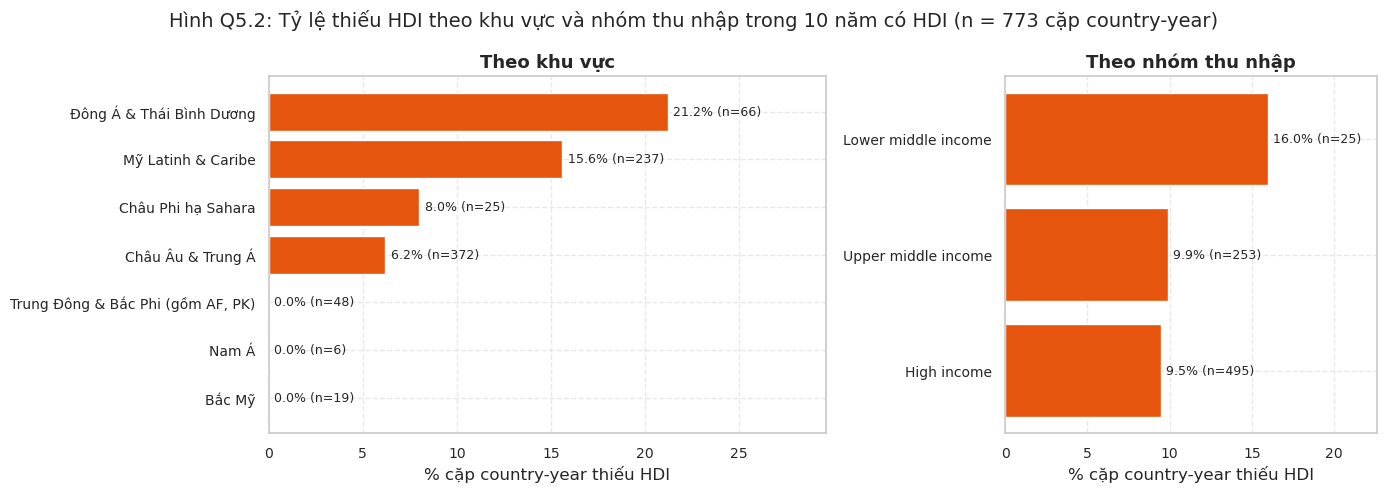

In [6]:
q5_h = q5[q5['in_hdi_year']]
q5_hcy = q5_h.drop_duplicates(['country', 'year'])


def q5_missing_by(col):
    # Tỷ lệ country-year thiếu HDI trong 10 năm có HDI
    t = q5_hcy.groupby(col).agg(
        so_quoc_gia=('country', 'nunique'),
        so_country_year=('country', 'size'),
        pct_thieu=('is_missing_hdi', 'mean'))
    t['pct_thieu'] = (100 * t['pct_thieu']).round(1)
    return t.sort_values('pct_thieu', ascending=False)


q5_miss_region = q5_missing_by('region_vi')
q5_miss_income = q5_missing_by('income_group')
display(q5_miss_region, q5_miss_income)

q5_never = q5_hcy.groupby('country')['is_missing_hdi'].all()
q5_never = q5_countries.set_index('country').loc[
    q5_never[q5_never].index, ['region_vi', 'income_group']]
q5_absent = sorted(set(q5['country']) - set(q5_h['country']))
print(f"Nước có mặt trong 10 năm có HDI nhưng không bao giờ có HDI: "
      f"{len(q5_never)}")
display(q5_never)
print("Nước không có dòng nào trong 10 năm có HDI:", q5_absent)

fig, axes = plt.subplots(1, 2, figsize=(14, 5),
                         gridspec_kw={'width_ratios': [3, 2]})
for ax, t, title in [(axes[0], q5_miss_region, 'Theo khu vực'),
                     (axes[1], q5_miss_income, 'Theo nhóm thu nhập')]:
    t = t.sort_values('pct_thieu')
    ax.barh(t.index, t['pct_thieu'], color='#e6550d')
    for i, (p, n) in enumerate(zip(t['pct_thieu'], t['so_country_year'])):
        ax.text(p + 0.3, i, f"{p:.1f}% (n={n})", va='center', fontsize=9)
    ax.set_xlabel('% cặp country-year thiếu HDI')
    ax.set_title(title)
    ax.set_xlim(0, t['pct_thieu'].max() * 1.35 + 1)
fig.suptitle('Hình Q5.2: Tỷ lệ thiếu HDI theo khu vực và nhóm thu nhập '
             f'trong 10 năm có HDI (n = {len(q5_hcy)} cặp country-year)')
fig.tight_layout()
save_figure(fig, '../data/processed/tv3_q5_fig2_missing_by_region.png')
plt.show()

**c) Độ lệch của complete-case (D3, D4).** Với mỗi nhóm, em so tỷ lệ gộp trên **mọi dòng** với tỷ lệ gộp trên **các dòng có HDI**:

$$\text{Bias}\% = \frac{\text{Rate}_{\text{Complete}} - \text{Rate}_{\text{All}}}{\text{Rate}_{\text{All}}} \times 100$$

Có hai phạm vi so sánh:

- **Toàn kỳ 1985–2015:** đúng với việc "xóa mọi dòng thiếu HDI". Độ lệch ở đây gộp cả hai nguồn thiếu, gồm cả tác động của việc chỉ còn 10 năm.
- **Trong 10 năm có HDI:** chỉ còn nguồn "thiếu theo nước". Đây là phạm vi chính để đánh giá thiên lệch chọn mẫu.

In [7]:
Q5_AGES = ['5-14 years', '15-24 years', '25-34 years', '35-54 years',
           '55-74 years', '75+ years']


def q5_bias_table(data, by):
    # Tỷ lệ gộp trên mọi dòng và trên các dòng có HDI, kèm Bias%
    cols = ['suicides_no', 'population']
    s_all = data.groupby(by)[cols].sum()
    s_cc = data[~data['is_missing_hdi']].groupby(by)[cols].sum()
    t = pd.DataFrame({
        'rate_all': 1e5 * s_all['suicides_no'] / s_all['population'],
        'rate_complete': 1e5 * s_cc['suicides_no'] / s_cc['population'],
    })
    t['bias_pct'] = 100 * (t['rate_complete'] - t['rate_all']) / t['rate_all']
    return t.round(2)


q5_overall = pd.DataFrame({
    'rate_all': [calculate_aggregated_rate(q5),
                 calculate_aggregated_rate(q5_h)],
    'rate_complete': [calculate_aggregated_rate(q5[~q5['is_missing_hdi']])] * 2,
}, index=['Toàn kỳ 1985–2015', 'Trong 10 năm có HDI'])
q5_overall['bias_pct'] = (100 * (q5_overall['rate_complete']
                                 - q5_overall['rate_all'])
                          / q5_overall['rate_all'])
print("Tổng thể:")
display(q5_overall.round(2))
print("Tỷ lệ gộp của riêng các dòng thiếu HDI trong 10 năm có HDI:",
      round(calculate_aggregated_rate(q5_h[q5_h['is_missing_hdi']]), 2))

q5_bias_age = pd.concat(
    {'Toàn kỳ': q5_bias_table(q5, 'age'),
     '10 năm có HDI': q5_bias_table(q5_h, 'age')}, axis=1).loc[Q5_AGES]
print("\nTheo nhóm tuổi:")
display(q5_bias_age)

q5_h = q5_h.assign(period=np.where(q5_h['year'] >= 2010,
                                   '2010–2014 (hằng năm)',
                                   '1985–2005 (5 năm/lần)'))
print("Trong 10 năm có HDI, theo khu vực, giới tính và giai đoạn:")
display(q5_bias_table(q5_h, 'region_vi').sort_values('bias_pct'))
display(q5_bias_table(q5_h, 'sex'))
display(q5_bias_table(q5_h, 'period'))

Tổng thể:


,rate_all,rate_complete,bias_pct
Toàn kỳ 1985–2015,13.15,11.13,-15.39
Trong 10 năm có HDI,12.68,11.13,-12.24


Tỷ lệ gộp của riêng các dòng thiếu HDI trong 10 năm có HDI: 25.93

Theo nhóm tuổi:


Toàn kỳ                        10 năm có HDI                \
            rate_all rate_complete bias_pct      rate_all rate_complete   
age                                                                       
5-14 years      0.62          0.58    -6.93          0.64          0.58   
15-24 years     9.36          8.09   -13.64          9.18          8.09   
25-34 years    13.33         10.82   -18.83         12.82         10.82   
35-54 years    17.07         14.05   -17.72         16.14         14.05   
55-74 years    18.85         15.97   -15.28         17.69         15.97   
75+ years      24.54         20.97   -14.58         22.95         20.97   

                      
            bias_pct  
age                   
5-14 years     -9.21  
15-24 years   -11.87  
25-34 years   -15.58  
35-54 years   -12.93  
55-74 years    -9.70  
75+ years      -8.66

Trong 10 năm có HDI, theo khu vực, giới tính và giai đoạn:


,rate_all,rate_complete,bias_pct
region_vi,,,
Châu Âu & Trung Á,15.74,13.06,-17.02
Đông Á & Thái Bình Dương,16.33,14.97,-8.31
Châu Phi hạ Sahara,1.32,1.31,-0.99
Mỹ Latinh & Caribe,5.63,5.61,-0.42
Bắc Mỹ,13.15,13.15,0.00
Nam Á,33.92,33.92,0.00
"Trung Đông & Bắc Phi (gồm AF, PK)",3.97,3.97,0.00


,rate_all,rate_complete,bias_pct
sex,,,
female,5.75,5.20,-9.52
male,19.94,17.29,-13.29


,rate_all,rate_complete,bias_pct
period,,,
1985–2005 (5 năm/lần),13.72,11.86,-13.56
2010–2014 (hằng năm),11.86,10.57,-10.94


**d) Kiểm định và khoảng tin cậy (D5).**

- **So sánh phân phối:** trong 10 năm có HDI, em gộp tỷ lệ về cấp country-year rồi so nhóm thiếu HDI với nhóm có HDI bằng **Mann-Whitney U** (so vị trí, không giả định phân phối chuẩn) và **Kolmogorov-Smirnov** (so toàn bộ hình dạng phân phối). Hai kiểm định này coi các country-year là độc lập, trong khi các năm của cùng một nước thì tương quan với nhau, nên p-value chỉ mang tính tham khảo.
- **Khoảng tin cậy cho Bias%:** dùng `cluster_bootstrap_ci` trong `src/utils.py`, lấy mẫu lại **theo quốc gia** 1,000 lần. Cách này giữ nguyên sự phụ thuộc giữa các năm trong cùng một nước.

In [8]:
# Kiểm định trên tỷ lệ gộp cấp country-year
q5_cyr = (q5_h.groupby(['country', 'year'])
          .agg(suicides_no=('suicides_no', 'sum'),
               population=('population', 'sum'),
               is_missing_hdi=('is_missing_hdi', 'first'))
          .reset_index())
q5_cyr['rate'] = 1e5 * q5_cyr['suicides_no'] / q5_cyr['population']
q5_miss_r = q5_cyr.loc[q5_cyr['is_missing_hdi'], 'rate']
q5_have_r = q5_cyr.loc[~q5_cyr['is_missing_hdi'], 'rate']
q5_mwu = stats.mannwhitneyu(q5_miss_r, q5_have_r, alternative='two-sided')
q5_ks = stats.ks_2samp(q5_miss_r, q5_have_r)
print(f"Country-year thiếu HDI: n = {len(q5_miss_r)}, "
      f"trung vị = {q5_miss_r.median():.2f}/100k")
print(f"Country-year có HDI:   n = {len(q5_have_r)}, "
      f"trung vị = {q5_have_r.median():.2f}/100k")
print(f"Mann-Whitney U: U = {q5_mwu.statistic:,.1f}, "
      f"p = {q5_mwu.pvalue:.4f}")
print(f"Kolmogorov-Smirnov: D = {q5_ks.statistic:.4f}, "
      f"p = {q5_ks.pvalue:.4f}")

# Kiểm định theo từng nhóm tuổi (tỷ lệ gộp hai giới, cấp country-year-age)
q5_cya = (q5_h.groupby(['country', 'year', 'age'])
          .agg(suicides_no=('suicides_no', 'sum'),
               population=('population', 'sum'),
               is_missing_hdi=('is_missing_hdi', 'first'))
          .reset_index())
q5_cya['rate'] = 1e5 * q5_cya['suicides_no'] / q5_cya['population']
q5_age_tests = []
for age in Q5_AGES:
    g = q5_cya[q5_cya['age'] == age]
    a = g.loc[g['is_missing_hdi'], 'rate']
    b = g.loc[~g['is_missing_hdi'], 'rate']
    q5_age_tests.append({
        'age': age, 'n_thieu': len(a), 'n_co': len(b),
        'trung_vi_thieu': round(a.median(), 2),
        'trung_vi_co': round(b.median(), 2),
        'p_mann_whitney': stats.mannwhitneyu(
            a, b, alternative='two-sided').pvalue,
    })
q5_age_tests = pd.DataFrame(q5_age_tests).set_index('age')
display(q5_age_tests.round(4))


def q5_bias_pct(data):
    # Bias% tổng thể của một tập dữ liệu (dùng cho bootstrap)
    r_all = calculate_aggregated_rate(data)
    r_cc = calculate_aggregated_rate(data[~data['is_missing_hdi']])
    return 100 * (r_cc - r_all) / r_all


q5_ci = cluster_bootstrap_ci(
    q5_h[['country', 'suicides_no', 'population', 'is_missing_hdi']],
    cluster_col='country', calc_func=q5_bias_pct,
    n_bootstraps=1000, random_state=42)
print(f"Bias% trong 10 năm có HDI: {q5_bias_pct(q5_h):.2f}% "
      f"(KTC 95% cluster bootstrap: {q5_ci[0]:.2f}% đến {q5_ci[1]:.2f}%)")

Country-year thiếu HDI: n = 76, trung vị = 8.53/100k
Country-year có HDI:   n = 697, trung vị = 10.35/100k
Mann-Whitney U: U = 25,028.5, p = 0.4306
Kolmogorov-Smirnov: D = 0.1189, p = 0.2639


,n_thieu,n_co,trung_vi_thieu,trung_vi_co,p_mann_whitney
age,,,,,
5-14 years,76,697,0.40,0.40,0.1240
15-24 years,76,697,7.01,7.33,0.1688
25-34 years,76,697,10.47,9.40,0.5716
35-54 years,76,697,12.65,12.52,0.9646
55-74 years,76,697,11.85,12.60,0.9890
75+ years,76,697,11.40,13.65,0.4833


Bias% trong 10 năm có HDI: -12.24% (KTC 95% cluster bootstrap: -29.07% đến 0.18%)


-> Đã lưu biểu đồ: ../data/processed/tv3_q5_fig3_bias_by_age.png


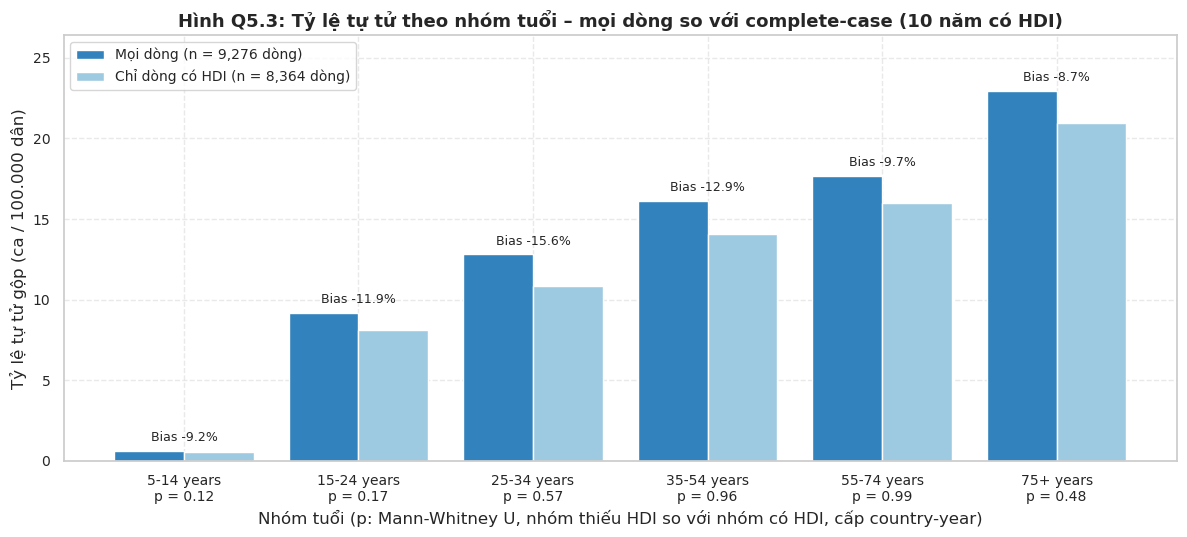

In [9]:
q5_plot = q5_bias_age['10 năm có HDI']
x = np.arange(len(Q5_AGES))
fig, ax = plt.subplots(figsize=(12, 5.5))
ax.bar(x - 0.2, q5_plot['rate_all'], width=0.4, color='#3182bd',
       label=f'Mọi dòng (n = {len(q5_h):,} dòng)')
ax.bar(x + 0.2, q5_plot['rate_complete'], width=0.4, color='#9ecae1',
       label=f'Chỉ dòng có HDI (n = {(~q5_h["is_missing_hdi"]).sum():,} dòng)')
for i, (top, b) in enumerate(zip(q5_plot[['rate_all', 'rate_complete']]
                                 .max(axis=1), q5_plot['bias_pct'])):
    ax.text(i, top + 0.6, f"Bias {b:+.1f}%", ha='center', fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels([f"{a}\np = {p:.2f}" for a, p in
                    zip(Q5_AGES, q5_age_tests['p_mann_whitney'])])
ax.set_xlabel('Nhóm tuổi (p: Mann-Whitney U, nhóm thiếu HDI so với nhóm '
              'có HDI, cấp country-year)')
ax.set_ylabel('Tỷ lệ tự tử gộp (ca / 100.000 dân)')
ax.set_ylim(0, q5_plot['rate_all'].max() * 1.15)
ax.set_title('Hình Q5.3: Tỷ lệ tự tử theo nhóm tuổi – mọi dòng so với '
             'complete-case (10 năm có HDI)')
ax.legend(loc='upper left')
fig.tight_layout()
save_figure(fig, '../data/processed/tv3_q5_fig3_bias_by_age.png')
plt.show()

**e) Kiểm tra độ vững (D6).** Tỷ lệ gộp bị chi phối bởi các nước đông dân, nên em kiểm tra Bias% (trong 10 năm có HDI) khi thay đổi cách tính:

1. **Bỏ Nga:** Nga đông dân, tỷ lệ cao và không bao giờ có HDI.
2. **Bỏ 9 nước không bao giờ có HDI:** chỉ còn các nước thiếu HDI ở một vài năm.
3. **Chỉ nước có độ phủ HDI > 80%** (độ phủ = tỷ lệ country-year có HDI trong 10 năm có HDI), và so với nhóm nước có độ phủ < 30%.
4. **Dùng trung vị** tỷ lệ cấp country-year thay cho tỷ lệ gộp.

Độ phủ HDI > 80%: 78 nước; < 30%: 9 nước; 30–80%: 12 nước
Tỷ lệ gộp nhóm độ phủ cao: 11.17; nhóm độ phủ thấp: 26.83 (ca/100k)


,so_nuoc,rate_all,rate_complete,bias_pct
"Chính: mọi nước, tỷ lệ gộp",99,12.68,11.13,-12.24
Bỏ Nga,98,11.46,11.13,-2.91
Bỏ 9 nước không bao giờ có HDI,90,11.13,11.13,-0.03
Chỉ nước có độ phủ HDI > 80%,78,11.17,11.17,-0.02
Trung vị country-year thay cho tỷ lệ gộp,99,10.06,10.35,2.88


-> Đã lưu biểu đồ: ../data/processed/tv3_q5_fig4_robustness.png


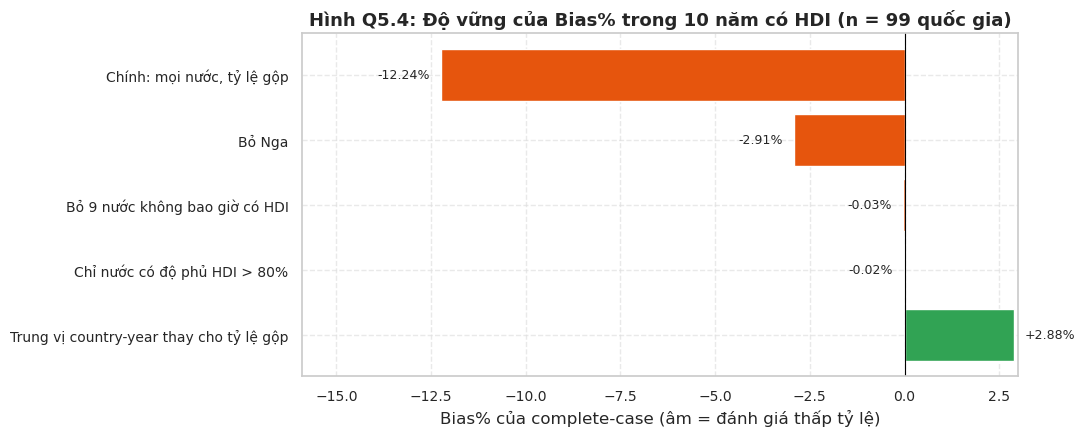

In [10]:
q5_cov = 1 - q5_hcy.groupby('country')['is_missing_hdi'].mean()
q5_high = q5_cov[q5_cov > 0.8].index
q5_low = q5_cov[q5_cov < 0.3].index
print(f"Độ phủ HDI > 80%: {len(q5_high)} nước; < 30%: {len(q5_low)} nước; "
      f"30–80%: {len(q5_cov) - len(q5_high) - len(q5_low)} nước")
print(f"Tỷ lệ gộp nhóm độ phủ cao: "
      f"{calculate_aggregated_rate(q5_h[q5_h['country'].isin(q5_high)]):.2f}"
      f"; nhóm độ phủ thấp: "
      f"{calculate_aggregated_rate(q5_h[q5_h['country'].isin(q5_low)]):.2f}"
      " (ca/100k)")

q5_variants = {
    'Chính: mọi nước, tỷ lệ gộp': q5_h,
    'Bỏ Nga': q5_h[q5_h['country'] != 'Russian Federation'],
    'Bỏ 9 nước không bao giờ có HDI':
        q5_h[~q5_h['country'].isin(q5_never.index)],
    'Chỉ nước có độ phủ HDI > 80%': q5_h[q5_h['country'].isin(q5_high)],
}
q5_robust = pd.DataFrame({
    name: {'so_nuoc': d['country'].nunique(),
           'rate_all': calculate_aggregated_rate(d),
           'rate_complete': calculate_aggregated_rate(
               d[~d['is_missing_hdi']]),
           'bias_pct': q5_bias_pct(d)}
    for name, d in q5_variants.items()}).T
q5_med_all = q5_cyr['rate'].median()
q5_med_cc = q5_have_r.median()
q5_robust.loc['Trung vị country-year thay cho tỷ lệ gộp'] = [
    q5_h['country'].nunique(), q5_med_all, q5_med_cc,
    100 * (q5_med_cc - q5_med_all) / q5_med_all]
q5_robust['so_nuoc'] = q5_robust['so_nuoc'].astype(int)
display(q5_robust.round(2))

fig, ax = plt.subplots(figsize=(11, 4.5))
q5_rb = q5_robust['bias_pct'][::-1]
ax.barh(q5_rb.index, q5_rb, color=np.where(q5_rb < 0, '#e6550d', '#31a354'))
for i, v in enumerate(q5_rb):
    ax.text(v - 0.3 if v < 0 else v + 0.3, i, f"{v:+.2f}%", va='center',
            ha='right' if v < 0 else 'left', fontsize=9)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlim(q5_rb.min() * 1.3, 3)
ax.set_xlabel('Bias% của complete-case (âm = đánh giá thấp tỷ lệ)')
ax.set_title('Hình Q5.4: Độ vững của Bias% trong 10 năm có HDI '
             f'(n = {q5_h["country"].nunique()} quốc gia)')
fig.tight_layout()
save_figure(fig, '../data/processed/tv3_q5_fig4_robustness.png')
plt.show()

#### 3.4. Q5 – Kết quả và thảo luận

> ✍️ **[TV3 tự viết trước khi khóa bài 27/11]** Trả lời câu hỏi Q5 bằng số liệu của các bảng và Hình Q5.1–Q5.4 ở trên: HDI thiếu theo cơ chế nào (MCAR hay không, bằng chứng nào), complete-case lệch bao nhiêu và lệch do đâu, kết quả có vững không, ý nghĩa thực tiễn cho người dùng mục tiêu, điểm bất ngờ và giới hạn (ví dụ: `income_group` là phân loại hiện tại; p-value coi country-year là độc lập).

## 3.5 · Tổng kết và phản tư

### 3.5.1 · Bằng chứng cho sáu câu hỏi

Q1–Q2 hiện có đặc tả của TV1. Ô dưới tính hai đối chiếu độc lập trên dữ liệu gốc phục vụ tổng hợp và slide. Q2 ghép nam và nữ trong cùng nước, năm và tuổi. Khoảng tin cậy 95% dùng 1.000 mẫu bootstrap lấy lại toàn bộ cụm quốc gia. Q3–Q5 lấy kết quả trực tiếp của notebook này. Q6 đối chiếu bảng test tại mục 3.4 của notebook 03.

In [18]:
import numpy as np

window = panel.loc[panel.year.between(1990, 2015)]
fixed = window.loc[window.groupby("country").year.transform("size").eq(26)]
def annual_rates(frame):
    counts = frame.groupby("year")[["cases", "pop"]].sum()
    return 100_000 * counts.cases / counts["pop"]

q1_trends = pd.DataFrame({"Có báo cáo": annual_rates(window), "Cố định": annual_rates(fixed)})
print(f"Q1 · Mẫu cố định gồm {fixed.country.nunique()} nước")
display(q1_trends.loc[[1990, 2015]].round(2))

sex_rates = full.assign(rate=100_000 * full.suicides_no / full.population).pivot(
    index=["country", "year", "age"], columns="sex", values="rate")
gap = (sex_rates.male - sex_rates.female).rename("gap")
grouped = gap.groupby(["country", "age"]).agg(["sum", "count"])
sums = grouped["sum"].unstack()[WHO.index]
counts = grouped["count"].unstack()[WHO.index]
rng = np.random.default_rng(42)
draws = rng.multinomial(len(sums), np.full(len(sums), 1 / len(sums)), size=1000)
interval = np.quantile((draws @ sums.values) / (draws @ counts.values), [.025, .975], axis=0)
q2_gaps = pd.DataFrame({"Nam trừ nữ": sums.sum() / counts.sum(),
                        "CI 2,5%": interval[0], "CI 97,5%": interval[1]})
display(q2_gaps.round(2))
display(q3_stats.round(3), pooled_delta.round(3), q5_overall.round(2))

Q1 · Mẫu cố định gồm 34 nước


,Có báo cáo,Cố định
year,,
1990,13.18,12.86
2015,11.47,12.07


,Nam trừ nữ,"CI 2,5%","CI 97,5%"
age,,,
5-14 years,0.32,0.20,0.43
15-24 years,9.23,7.68,10.79
25-34 years,15.24,12.71,17.70
35-54 years,18.07,15.04,21.21
55-74 years,18.06,15.15,21.02
75+ years,28.08,23.49,32.47


,Số cặp,Số nước,Pearson r,Spearman ρ,Δ tỷ lệ / +10% GDP
Mẫu,,,,,
1 năm,2148,96,-0.029,-0.054,-0.045
2 năm,2028,94,-0.074,-0.098,-0.077
"1 năm, |ΔGDP| ≤ 20%",1828,96,-0.013,-0.016,-0.029
"1 năm, GDP thấp",655,32,-0.014,-0.075,-0.024
"1 năm, GDP trung bình",735,32,-0.064,-0.067,-0.101
"1 năm, GDP cao",758,32,-0.004,-0.020,-0.006


,Δ WHO,Δ Mẫu,Δ Thô,Cơ cấu tuổi,Tỷ lệ theo tuổi,Cơ cấu / Δ thô (%),Δ dân số 55+ (điểm %)
country,,,,,,,
Tất cả nước trong mẫu,-2.607,-2.81,-2.087,0.809,-2.896,-38.751,4.61


,rate_all,rate_complete,bias_pct
Toàn kỳ 1985–2015,13.15,11.13,-15.39
Trong 10 năm có HDI,12.68,11.13,-12.24


**Bảng đối chiếu kết quả cho phần thảo luận**

| Câu hỏi | Kết quả quan sát |
| --- | --- |
| Q1–Q2 | Từ 1990 đến 2015, tỷ lệ trên mọi nước có báo cáo đi từ 13,18 xuống 11,47 ca/100.000. Với 34 nước cố định, hai mức là 12,86 và 12,07. Ở nhóm 75+, chênh lệch nam trừ nữ trung bình trong cùng nước–năm là 28,08 ca/100.000 (KTC 95% 23,49–32,47). Đây là phép tính đối chiếu của TV2. |
| Q3 | Với 2.148 cặp năm, hệ số dốc ứng với tăng trưởng GDP cao hơn 10 điểm phần trăm là −0,045 ca/100.000. Bỏ các cú sốc trên 20% theo trị tuyệt đối cho hệ số −0,029. Ở nhóm GDP cao, hệ số là −0,006. |
| Q4 | Tại 49 nước đủ dữ liệu, tỷ lệ thô giảm 2,09 ca/100.000, còn ASR giảm 2,61 theo chuẩn WHO và 2,81 theo chuẩn mẫu. Điểm đáng chú ý là cơ cấu tuổi đóng góp **+0,81** trong khi thay đổi tỷ lệ riêng theo tuổi đóng góp **−2,90**. Hai thành phần ngược dấu giải thích vì sao mức giảm thô nhỏ hơn mức giảm chuẩn hóa. |
| Q5–Q6 | Trong 10 năm có HDI, giữ các dòng đủ HDI đưa tỷ lệ gộp từ 12,68 xuống 11,13 (−12,24%, KTC 95% −29,07% đến +0,18%). Trong đánh giá dự báo của TV3, MAE giảm từ 2,213 xuống 2,065 ca/100.000 trên 4.428 mẫu test. |

Các giá trị Q5–Q6 tham chiếu kết quả trên nhánh TV3 tại `8f98551`. Mục Q5 ở trên và bảng test của notebook 03 cho phép đối chiếu khi chạy lại bằng phiên bản thư viện khác.

### 3.5.2 · Giới hạn

- Tỷ lệ gộp phụ thuộc vào nước tham gia báo cáo và quy mô dân số. Hai giai đoạn của Q4 chỉ mô tả các nước có đủ quan sát ở cả hai cửa sổ.
- GDP danh nghĩa bằng USD chịu tác động của tỷ giá và lạm phát. Sai phân nội bộ vẫn chịu ảnh hưởng của yếu tố thay đổi theo năm.
- ASR giới hạn ở dân số từ 5 tuổi. Nhóm tuổi rộng và việc gộp hai giới có thể che khuất thay đổi bên trong từng nhóm.
- HDI thiếu theo thời điểm và quốc gia. Kết quả dự báo đánh giá trên nhóm dân số và các năm có quan sát liên tiếp.

### 3.5.3 · Hướng mở rộng

Đối chiếu GDP thực theo sức mua tương đương, phân rã riêng theo tuổi và giới, kiểm tra độ nhạy với các nước vắng mặt và đánh giá dự báo trên các năm sau 2015.

### 3.5.4 · Phản tư cá nhân

**Bản nháp kỹ thuật do Codex hỗ trợ, TV2 cần duyệt.** Hai quyết định ảnh hưởng trực tiếp tới kết quả là cách xử lý khoảng trống thời gian và cách chọn dân số chuẩn. Với Q3, lấy dòng trước bằng vị trí có thể ghép hai năm cách xa nhau. Ghép khóa quốc gia và năm lịch giúp kiểm tra được 2.148 cặp một năm; phép ghép hai năm tạo ra 2.028 cặp. Với Q4, bộ dữ liệu bắt đầu từ 5 tuổi nên trọng số WHO phải được gộp lại theo sáu nhóm và chuẩn hóa trên cùng dải tuổi. Đẳng thức giữa hai thành phần phân rã và thay đổi tỷ lệ thô là phép kiểm tra có thể chạy lại khi đổi mẫu. Kinh nghiệm kỹ thuật có thể rút ra là xác định khóa, mẫu số và dân số tham chiếu trước khi đọc chiều biến động trên biểu đồ.

TV2 tự xác nhận trải nghiệm cá nhân và diễn giải cuối cùng trước khi nộp. Phản tư của TV1 và TV3 do từng thành viên cung cấp.